# ShopExpress — Comparaison finale équitable : variables originales vs enrichies

**Objectif :** comparer les deux configurations sur les mêmes commandes et les mêmes partitions train/validation/test.  
**Cible :** `Reached.on.Time_Y.N` — **1 = livraison en retard, 0 = livraison à temps**.

Ce notebook ne remplace pas les notebooks existants. Il sert à produire une comparaison finale contrôlée avant de choisir le modèle.


## 1. Préparation

Placez `Original.csv` et `shop.csv` dans le même dossier que ce notebook.  
`shop.csv` doit contenir les 10 variables originales et les 6 variables enrichies. Les deux fichiers doivent correspondre aux mêmes commandes; l'alignement est fait par `ID`.


In [1]:
%pip install -q pandas numpy matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
TARGET = "Reached.on.Time_Y.N"
ORIGINAL_FEATURES = [
    "Warehouse_block", "Mode_of_Shipment", "Customer_care_calls",
    "Customer_rating", "Cost_of_the_Product", "Prior_purchases",
    "Product_importance", "Gender", "Discount_offered", "Weight_in_gms"
]
ENRICHED_FEATURES = ORIGINAL_FEATURES + [
    "Distance_km", "Weather_Condition", "Traffic_Level",
    "Route_Complexity", "Customer_Country", "Product_Category"
]


## 2. Chargement et vérifications des données

In [3]:
original = pd.read_csv("Original.csv")
enriched = pd.read_csv("shop.csv")

required_original = ["ID", TARGET] + ORIGINAL_FEATURES
required_enriched = ["ID", TARGET] + ENRICHED_FEATURES

missing_original = sorted(set(required_original) - set(original.columns))
missing_enriched = sorted(set(required_enriched) - set(enriched.columns))
if missing_original:
    raise ValueError(f"Colonnes manquantes dans Original.csv : {missing_original}")
if missing_enriched:
    raise ValueError(f"Colonnes manquantes dans shop.csv : {missing_enriched}")

# Alignement explicite par ID : aucun appariement implicite par position.
base = original[required_original].copy()
extra = enriched[["ID"] + [c for c in ENRICHED_FEATURES if c not in ORIGINAL_FEATURES] + [TARGET]].copy()
if base["ID"].duplicated().any() or extra["ID"].duplicated().any():
    raise ValueError("ID en double : impossible de garantir l'alignement.")

merged = base.merge(
    extra.drop(columns=[TARGET]),
    on="ID", how="inner", validate="one_to_one"
)
target_check = base[["ID", TARGET]].merge(
    enriched[["ID", TARGET]], on="ID", suffixes=("_original", "_enrichi"),
    how="inner", validate="one_to_one"
)
if len(merged) != len(base) or len(merged) != len(enriched):
    raise ValueError("Les deux fichiers ne contiennent pas exactement les mêmes ID.")
if not (target_check[f"{TARGET}_original"] == target_check[f"{TARGET}_enrichi"]).all():
    raise ValueError("Les cibles diffèrent entre les deux fichiers.")

merged = merged.sort_values("ID").reset_index(drop=True)
y = merged[TARGET].astype(int)
if not set(y.unique()).issubset({0, 1}):
    raise ValueError("La cible doit être codée 0/1.")

print("Lignes alignées :", len(merged))
print("Variables originales :", len(ORIGINAL_FEATURES))
print("Variables enrichies :", len(ENRICHED_FEATURES))
print("Convention : 1 = retard ; 0 = à temps")
print(y.value_counts().sort_index().rename(index={0:"À temps (0)", 1:"En retard (1)"}))


Lignes alignées : 10999
Variables originales : 10
Variables enrichies : 16
Convention : 1 = retard ; 0 = à temps
Reached.on.Time_Y.N
À temps (0)      4436
En retard (1)    6563
Name: count, dtype: int64


## 3. Partition commune

Les indices sont créés une seule fois puis réutilisés pour les deux configurations. Ainsi, les deux modèles sont évalués sur exactement les mêmes commandes.


In [4]:
indices = np.arange(len(merged))
idx_train, idx_temp = train_test_split(
    indices, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
idx_valid, idx_test = train_test_split(
    idx_temp, test_size=0.50, random_state=RANDOM_STATE,
    stratify=y.iloc[idx_temp]
)
print("Train / validation / test :", len(idx_train), len(idx_valid), len(idx_test))
print("Proportion classe 1 :", *(round(float(y.iloc[idx].mean()), 4)
      for idx in [idx_train, idx_valid, idx_test]))


Train / validation / test : 7699 1650 1650
Proportion classe 1 : 0.5967 0.597 0.5964


## 4. Prétraitement et modèles

Les transformations sont dans un pipeline et sont ajustées à l'intérieur de chaque pli d'entraînement. Le score de sélection est le F1 de la classe 1 (retard).


In [10]:
def make_pipeline(X_train, estimator):
    numeric = X_train.select_dtypes(include=np.number).columns.tolist()
    categorical = X_train.select_dtypes(exclude=np.number).columns.tolist()

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    preprocessor = ColumnTransformer(
    [
        ("num", numeric_pipe, numeric),
        ("cat", categorical_pipe, categorical)
    ],
    sparse_threshold=0
)
    return Pipeline([("preprocessor", preprocessor), ("model", estimator)])

def metric_row(y_true, probabilities, threshold, config, model_name, split_name):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Configuration": config,
        "Modèle": model_name,
        "Jeu": split_name,
        "Seuil": float(threshold),
        "Accuracy": accuracy_score(y_true, predictions),
        "Précision_retard": precision_score(y_true, predictions, pos_label=1, zero_division=0),
        "Rappel_retard": recall_score(y_true, predictions, pos_label=1, zero_division=0),
        "F1_retard": f1_score(y_true, predictions, pos_label=1, zero_division=0),
        "F1_macro": f1_score(y_true, predictions, average="macro", zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities)
    }

param_grids = {
    "Régression logistique": (
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]}
    ),
    "Arbre de décision": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"model__max_depth": [4, 8, 12, None],
         "model__min_samples_leaf": [3, 5, 10, 20],
         "model__class_weight": [None, "balanced"]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"model__n_estimators": [100, 200],
         "model__max_depth": [8, 15, None],
         "model__min_samples_leaf": [3, 5, 10],
         "model__class_weight": [None, "balanced"]}
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"model__n_estimators": [100, 200],
         "model__learning_rate": [0.03, 0.05, 0.1],
         "model__max_depth": [2, 3],
         "model__min_samples_leaf": [5, 10]}
    )
}


## 5. Optimisation séparée des deux configurations

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
feature_sets = {
    "Originales (10)": ORIGINAL_FEATURES,
    "Enrichies (16)": ENRICHED_FEATURES
}
fitted = {}
validation_rows = []
test_rows = []
threshold_rows = []

for config_name, features in feature_sets.items():
    X = merged[features]
    X_train = X.iloc[idx_train]
    X_valid = X.iloc[idx_valid]
    X_test = X.iloc[idx_test]
    y_train = y.iloc[idx_train]
    y_valid = y.iloc[idx_valid]
    y_test = y.iloc[idx_test]

    for model_name, (estimator, grid) in param_grids.items():
        pipe = make_pipeline(X_train, estimator)
        search = GridSearchCV(
            pipe, grid, scoring="f1", cv=cv, n_jobs=-1, refit=True
        )
        search.fit(X_train, y_train)
        model = search.best_estimator_

        p_valid = model.predict_proba(X_valid)[:, 1]
        # Seuil choisi uniquement sur validation.
        from sklearn.metrics import precision_recall_curve
        precision, recall, thresholds = precision_recall_curve(y_valid, p_valid, pos_label=1)
        f1_values = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
        best_idx = int(np.argmax(f1_values))
        tuned_threshold = float(thresholds[best_idx])

        validation_rows.append({
            "Configuration": config_name,
            "Modèle": model_name,
            "F1_CV": float(search.best_score_),
            "F1_validation_seuil_050": f1_score(y_valid, (p_valid >= 0.5).astype(int), zero_division=0),
            "F1_validation_seuil_optimisé": float(f1_values[best_idx]),
            "Seuil_validation": tuned_threshold,
            "Meilleurs_paramètres": json.dumps(search.best_params_, default=str)
        })

        p_test = model.predict_proba(X_test)[:, 1]
        test_rows.append(metric_row(y_test, p_test, 0.5, config_name, model_name, "Test — seuil 0,50"))
        test_rows.append(metric_row(y_test, p_test, tuned_threshold, config_name, model_name, "Test — seuil validation"))

        fitted[(config_name, model_name)] = {
            "model": model, "features": features,
            "threshold": tuned_threshold, "best_params": search.best_params_,
            "valid_f1_tuned": float(f1_values[best_idx])
        }

validation_results = pd.DataFrame(validation_rows).sort_values(
    "F1_validation_seuil_optimisé", ascending=False
)
test_results = pd.DataFrame(test_rows)
display(validation_results.round(4))


,Configuration,Modèle,F1_CV,F1_validation_seuil_050,F1_validation_seuil_optimisé,Seuil_validation,Meilleurs_paramètres
3,Originales (10),Gradient Boosting,0.6922,0.7037,0.7497,0.4126,"{""model__learning_rate"": 0.03, ""model__max_dep..."
6,Enrichies (16),Random Forest,0.6894,0.6755,0.7495,0.3498,"{""model__class_weight"": null, ""model__max_dept..."
7,Enrichies (16),Gradient Boosting,0.6914,0.7037,0.7492,0.4173,"{""model__learning_rate"": 0.03, ""model__max_dep..."
0,Originales (10),Régression logistique,0.7009,0.7078,0.7483,0.3284,"{""model__C"": 0.01, ""model__class_weight"": null}"
4,Enrichies (16),Régression logistique,0.6999,0.7061,0.7481,0.2766,"{""model__C"": 0.01, ""model__class_weight"": null}"
1,Originales (10),Arbre de décision,0.7090,0.6797,0.7476,0.0000,"{""model__class_weight"": ""balanced"", ""model__ma..."
2,Originales (10),Random Forest,0.6868,0.6624,0.7476,0.2099,"{""model__class_weight"": null, ""model__max_dept..."
5,Enrichies (16),Arbre de décision,0.7069,0.6867,0.7476,0.0000,"{""model__class_weight"": ""balanced"", ""model__ma..."


## 6. Comparaison finale sur le test

In [12]:
# Le meilleur candidat est sélectionné sur validation, jamais sur le test.
best_candidate = validation_results.iloc[0]
best_key = (best_candidate["Configuration"], best_candidate["Modèle"])
best_info = fitted[best_key]

print("Candidat retenu sur validation :", best_key)
print("Seuil choisi sur validation :", round(best_info["threshold"], 4))
display(
    test_results[
        (test_results["Configuration"] == best_key[0]) &
        (test_results["Modèle"] == best_key[1])
    ].round(4)
)

# Tableau de comparaison des meilleurs modèles par configuration.
best_by_config = validation_results.loc[
    validation_results.groupby("Configuration")["F1_validation_seuil_optimisé"].idxmax()
]
display(best_by_config[[
    "Configuration", "Modèle", "F1_CV",
    "F1_validation_seuil_optimisé", "Seuil_validation"
]].round(4))

comparison = test_results.merge(
    best_by_config[["Configuration", "Modèle", "Seuil_validation"]],
    on=["Configuration", "Modèle"], how="inner"
)
display(comparison.round(4))


Candidat retenu sur validation : ('Originales (10)', 'Gradient Boosting')
Seuil choisi sur validation : 0.4126


,Configuration,Modèle,Jeu,Seuil,Accuracy,Précision_retard,Rappel_retard,F1_retard,F1_macro,ROC_AUC
6,Originales (10),Gradient Boosting,"Test — seuil 0,50",0.5000,0.6527,0.7652,0.6026,0.6742,0.6512,0.7329
7,Originales (10),Gradient Boosting,Test — seuil validation,0.4126,0.6048,0.6089,0.9431,0.7400,0.4584,0.7329


,Configuration,Modèle,F1_CV,F1_validation_seuil_optimisé,Seuil_validation
6,Enrichies (16),Random Forest,0.6894,0.7495,0.3498
3,Originales (10),Gradient Boosting,0.6922,0.7497,0.4126


,Configuration,Modèle,Jeu,Seuil,Accuracy,Précision_retard,Rappel_retard,F1_retard,F1_macro,ROC_AUC,Seuil_validation
0,Originales (10),Gradient Boosting,"Test — seuil 0,50",0.5000,0.6527,0.7652,0.6026,0.6742,0.6512,0.7329,0.4126
1,Originales (10),Gradient Boosting,Test — seuil validation,0.4126,0.6048,0.6089,0.9431,0.7400,0.4584,0.7329,0.4126
2,Enrichies (16),Random Forest,"Test — seuil 0,50",0.5000,0.6667,0.7940,0.5955,0.6806,0.6660,0.7388,0.3498
3,Enrichies (16),Random Forest,Test — seuil validation,0.3498,0.6109,0.6074,0.9827,0.7508,0.4320,0.7388,0.3498


## 7. Matrices de confusion des deux candidats

Pour chaque configuration, on examine son meilleur modèle choisi sur validation, au seuil 0,50 et au seuil optimisé sur validation.


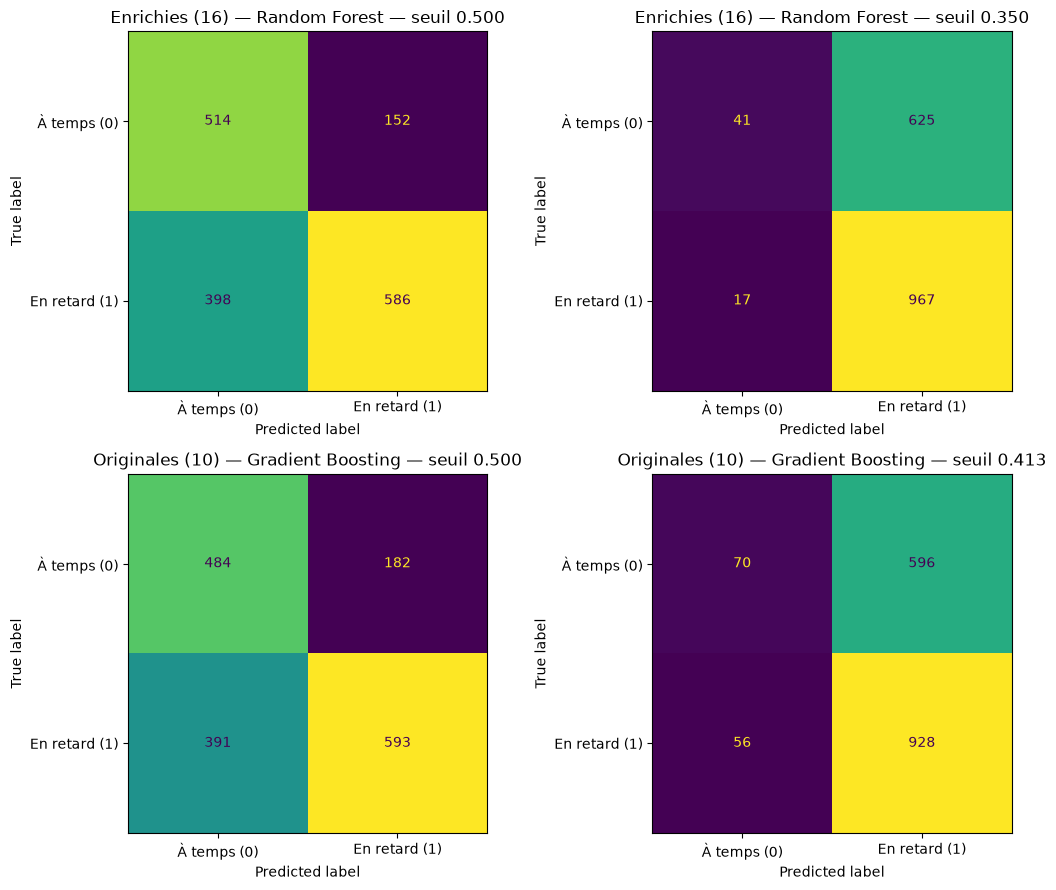

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row_i, (_, row) in enumerate(best_by_config.iterrows()):
    config_name, model_name = row["Configuration"], row["Modèle"]
    info = fitted[(config_name, model_name)]
    X_test = merged.iloc[idx_test][info["features"]]
    y_test = y.iloc[idx_test]
    probs = info["model"].predict_proba(X_test)[:, 1]
    for col_i, threshold in enumerate([0.5, info["threshold"]]):
        preds = (probs >= threshold).astype(int)
        ConfusionMatrixDisplay.from_predictions(
            y_test, preds, labels=[0, 1],
            display_labels=["À temps (0)", "En retard (1)"],
            values_format="d", ax=axes[row_i, col_i], colorbar=False
        )
        axes[row_i, col_i].set_title(f"{config_name} — {model_name} — seuil {threshold:.3f}")
plt.tight_layout()
plt.show()


## 8. Sauvegarde des résultats

Les fichiers exportés documentent la comparaison. Ils ne remplacent pas les runs MLflow déjà enregistrés.


In [9]:
validation_results.to_csv("comparaison_validation_original_vs_enrichi.csv", index=False)
test_results.to_csv("comparaison_test_original_vs_enrichi.csv", index=False)
best_by_config.to_csv("meilleurs_modeles_par_configuration.csv", index=False)
print("Fichiers de comparaison exportés.")


Fichiers de comparaison exportés.


## 9. Règle de décision et interprétation

- Ne retenez pas automatiquement le seuil qui maximise le F1 de la classe 1 : un seuil très bas peut prédire presque toutes les commandes « en retard ».
- Regardez ensemble le F1 de la classe 1, la précision, le rappel, le F1 macro, l'accuracy et les matrices de confusion.
- Un modèle enrichi n'est préférable que si ses variables sont disponibles au moment réel où la prédiction doit être faite. Des variables connues seulement après la livraison créeraient une fuite de données.
- Le jeu de test sert à comparer les candidats finaux; ne réajustez pas les hyperparamètres après avoir observé ses résultats.
- Si les variables enrichies n'améliorent pas clairement le résultat sur le test, privilégiez la solution originale, plus simple.
